In [60]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import EarlyStopping


In [61]:
random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

os.makedirs("results", exist_ok=True)
os.makedirs(os.path.join("results", "summary"), exist_ok=True)


In [62]:
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

X_train = X_train.reshape(-1, 28, 28, 1).astype("float32")
X_test  = X_test.reshape(-1, 28, 28, 1).astype("float32")

X_train /= 255.0
X_test  /= 255.0

y_train = keras.utils.to_categorical(y_train, 10)
y_test  = keras.utils.to_categorical(y_test, 10)

X_val, y_val = X_test, y_test


In [63]:
EPOCHS = 10
BATCH_SIZE = 100

L1_RATE = 1e-5
L2_RATE = 1e-5
DROPOUT_RATE = 0.30

SCENARIO_EXTRA_LAYERS = {
    "L1": lambda: [layers.Dense(64, activation="relu", kernel_regularizer=regularizers.l1(L1_RATE))],
    "L2": lambda: [layers.Dense(64, activation="relu", kernel_regularizer=regularizers.l2(L2_RATE))],
    "Dropout": lambda: [
        layers.Dense(64, activation="relu"),
        layers.Dropout(DROPOUT_RATE),
    ],
    "L1_Dropout": lambda: [
        layers.Dense(64, activation="relu", kernel_regularizer=regularizers.l1(L1_RATE)),
        layers.Dropout(DROPOUT_RATE),
    ],
}
DEFAULT_LAYERS = lambda: [layers.Dense(64, activation="relu")]

In [64]:
def build_model(scenario):
    model = keras.Sequential(name=scenario)
    model.add(layers.Input(shape=(28, 28, 1)))
    model.add(layers.Flatten())

    for layer in SCENARIO_EXTRA_LAYERS.get(scenario, DEFAULT_LAYERS)():
        model.add(layer)

    model.add(layers.Dense(10, activation="softmax"))
    model.compile(
        optimizer="adam",
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

In [65]:
def run_scenario(scenario, early_stopping=False):
    model = build_model(scenario)
    print(f"SCENARIO: {scenario}")
    model.summary()

    summary_lines = []
    model.summary(print_fn=lambda line: summary_lines.append(line))
    with open(os.path.join("results", "summary", f"{scenario}.txt"), "w", encoding="utf-8") as f:
        f.write("\n".join(summary_lines))

    callbacks = [
        EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True,
            verbose=1,
        )
    ] if early_stopping else []

    history = model.fit(
        X_train,
        y_train,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        validation_data=(X_val, y_val),
        callbacks=callbacks,
        verbose=1
    )

    test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)

    print(f"Test loss     : {test_loss:.6f}")
    print(f"Test accuracy : {test_accuracy:.6f}")
    print(f"Epochs run    : {len(history.history['loss'])}")

    epochs = range(1, len(history.history["loss"]) + 1)

    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(10, 3.5))

    ax_loss.plot(epochs, history.history["loss"], label="Training")
    ax_loss.plot(epochs, history.history["val_loss"], label="Validation")
    ax_loss.set_xlabel("Epoch")
    ax_loss.set_ylabel("Loss")
    ax_loss.set_title(f"{scenario} - Loss")
    ax_loss.legend()

    ax_acc.plot(epochs, history.history["accuracy"], label="Training")
    ax_acc.plot(epochs, history.history["val_accuracy"], label="Validation")
    ax_acc.set_xlabel("Epoch")
    ax_acc.set_ylabel("Accuracy")
    ax_acc.set_title(f"{scenario} - Accuracy")
    ax_acc.legend()

    fig.tight_layout()
    plt.show()

    return {
        "scenario": scenario,
        "test_loss": test_loss,
        "test_accuracy": test_accuracy,
        "epochs_run": len(history.history["loss"]),
        "history": history.history,
    }


## Baseline

SCENARIO: baseline


Model: "baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_25 (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_50 (Dense)                │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_51 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8896 - loss: 0.3959 - val_accuracy: 0.9371 - val_loss: 0.2226
Epoch 2/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9444 - loss: 0.1942 - val_accuracy: 0.9539 - val_loss: 0.1595
Epoch 3/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9582 - loss: 0.1427 - val_accuracy: 0.9640 - val_loss: 0.1289
Epoch 4/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9670 - loss: 0.1138 - val_accuracy: 0.9674 - val_loss: 0.1126
Epoch 5/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9732 - loss: 0.0947 - val_accuracy: 0.9698 - val_loss: 0.1025
Epoch 6/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9775 - loss: 0.0810 - val_accuracy: 0.9712 - val_loss: 0.0964
Epoch 7/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9805 - loss: 0.0707 - val_accuracy: 0.9718 - val_loss: 0.0926
Epoch 8/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9826 - loss: 0.0624 - val_accuracy: 0.

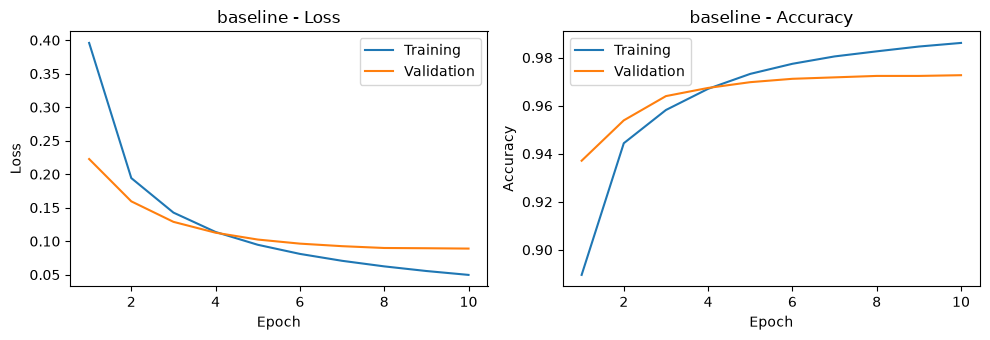

In [66]:
results = []
results.append(run_scenario("baseline"))

## L1 regularization

SCENARIO: L1


Model: "L1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_26 (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_52 (Dense)                │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_53 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8933 - loss: 0.4112 - val_accuracy: 0.9397 - val_loss: 0.2269
Epoch 2/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9463 - loss: 0.2083 - val_accuracy: 0.9522 - val_loss: 0.1784
Epoch 3/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9585 - loss: 0.1671 - val_accuracy: 0.9599 - val_loss: 0.1538
Epoch 4/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9654 - loss: 0.1420 - val_accuracy: 0.9640 - val_loss: 0.1394
Epoch 5/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9703 - loss: 0.1250 - val_accuracy: 0.9667 - val_loss: 0.1305
Epoch 6/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9741 - loss: 0.1122 - val_accuracy: 0.9687 - val_loss: 0.1246
Epoch 7/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9771 - loss: 0.1022 - val_accuracy: 0.9696 - val_loss: 0.1210
Epoch 8/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9800 - loss: 0.0941 - val_accuracy: 0.

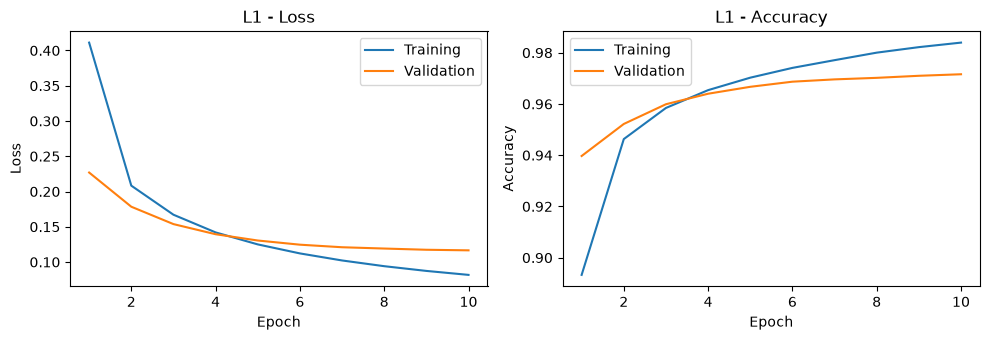

In [67]:
results.append(run_scenario("L1"))


L2 regularization

SCENARIO: L2


Model: "L2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_27 (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_54 (Dense)                │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_55 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8961 - loss: 0.3829 - val_accuracy: 0.9407 - val_loss: 0.2073
Epoch 2/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9475 - loss: 0.1869 - val_accuracy: 0.9565 - val_loss: 0.1518
Epoch 3/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9607 - loss: 0.1411 - val_accuracy: 0.9632 - val_loss: 0.1268
Epoch 4/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9686 - loss: 0.1149 - val_accuracy: 0.9669 - val_loss: 0.1129
Epoch 5/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9737 - loss: 0.0970 - val_accuracy: 0.9699 - val_loss: 0.1028
Epoch 6/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9773 - loss: 0.0839 - val_accuracy: 0.9706 - val_loss: 0.0978
Epoch 7/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9807 - loss: 0.0737 - val_accuracy: 0.9721 - val_loss: 0.0937
Epoch 8/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9832 - loss: 0.0654 - val_accuracy: 0.

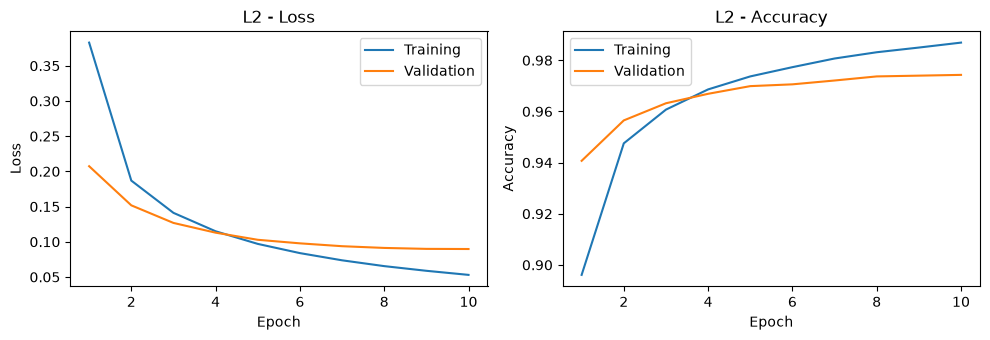

In [68]:
results.append(run_scenario("L2"))

## Dropout

SCENARIO: Dropout


Model: "Dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_28 (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_56 (Dense)                │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_57 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8526 - loss: 0.5032 - val_accuracy: 0.9330 - val_loss: 0.2359
Epoch 2/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9214 - loss: 0.2703 - val_accuracy: 0.9487 - val_loss: 0.1767
Epoch 3/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9353 - loss: 0.2207 - val_accuracy: 0.9565 - val_loss: 0.1493
Epoch 4/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9438 - loss: 0.1929 - val_accuracy: 0.9612 - val_loss: 0.1315
Epoch 5/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9470 - loss: 0.1768 - val_accuracy: 0.9630 - val_loss: 0.1222
Epoch 6/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9517 - loss: 0.1625 - val_accuracy: 0.9658 - val_loss: 0.1148
Epoch 7/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9541 - loss: 0.1505 - val_accuracy: 0.9679 - val_loss: 0.1107
Epoch 8/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9581 - loss: 0.1424 - val_accuracy: 0.

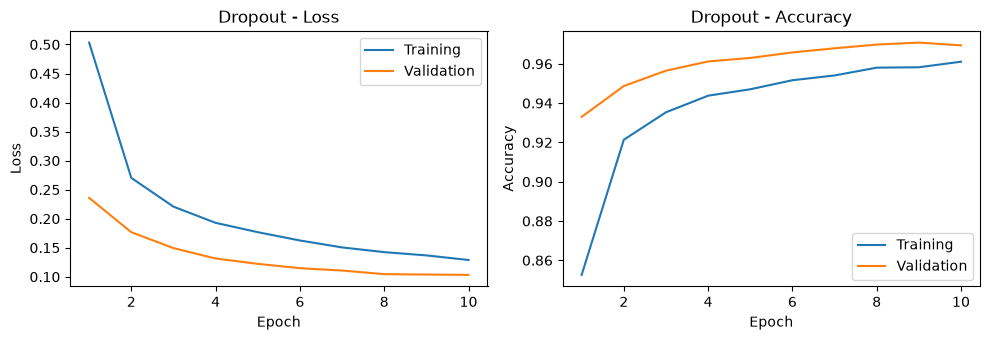

In [69]:
results.append(run_scenario("Dropout"))

## Early stopping

SCENARIO: EarlyStopping


Model: "EarlyStopping"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_29 (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_58 (Dense)                │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_59 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8916 - loss: 0.3958 - val_accuracy: 0.9357 - val_loss: 0.2179
Epoch 2/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9463 - loss: 0.1918 - val_accuracy: 0.9529 - val_loss: 0.1587
Epoch 3/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9591 - loss: 0.1433 - val_accuracy: 0.9610 - val_loss: 0.1311
Epoch 4/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9664 - loss: 0.1166 - val_accuracy: 0.9654 - val_loss: 0.1174
Epoch 5/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9714 - loss: 0.0988 - val_accuracy: 0.9681 - val_loss: 0.1083
Epoch 6/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9750 - loss: 0.0854 - val_accuracy: 0.9701 - val_loss: 0.1021
Epoch 7/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9785 - loss: 0.0747 - val_accuracy: 0.9707 - val_loss: 0.0981
Epoch 8/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9813 - loss: 0.0660 - val_accuracy: 0.

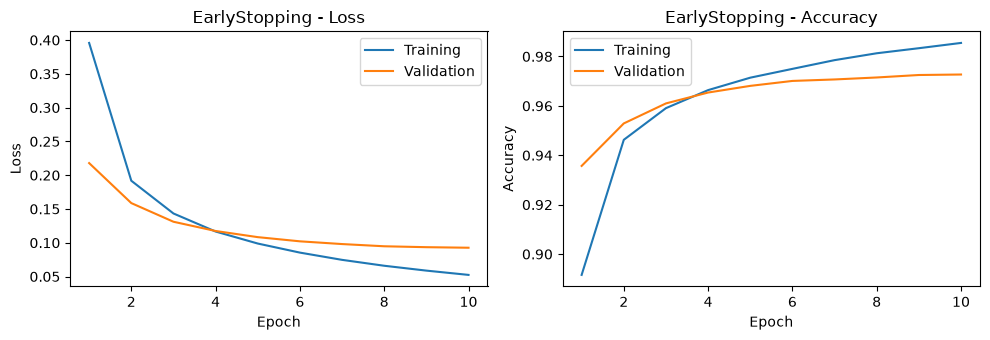

In [70]:
results.append(run_scenario("EarlyStopping", early_stopping=True))

## L1 + Dropout

SCENARIO: L1_Dropout


Model: "L1_Dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_30 (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_60 (Dense)                │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_61 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8566 - loss: 0.5101 - val_accuracy: 0.9355 - val_loss: 0.2426
Epoch 2/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9240 - loss: 0.2836 - val_accuracy: 0.9488 - val_loss: 0.1933
Epoch 3/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9352 - loss: 0.2423 - val_accuracy: 0.9565 - val_loss: 0.1653
Epoch 4/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9429 - loss: 0.2148 - val_accuracy: 0.9628 - val_loss: 0.1493
Epoch 5/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9487 - loss: 0.1991 - val_accuracy: 0.9646 - val_loss: 0.1424
Epoch 6/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9507 - loss: 0.1885 - val_accuracy: 0.9659 - val_loss: 0.1363
Epoch 7/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9538 - loss: 0.1789 - val_accuracy: 0.9682 - val_loss: 0.1298
Epoch 8/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9566 - loss: 0.1709 - val_accuracy: 0.

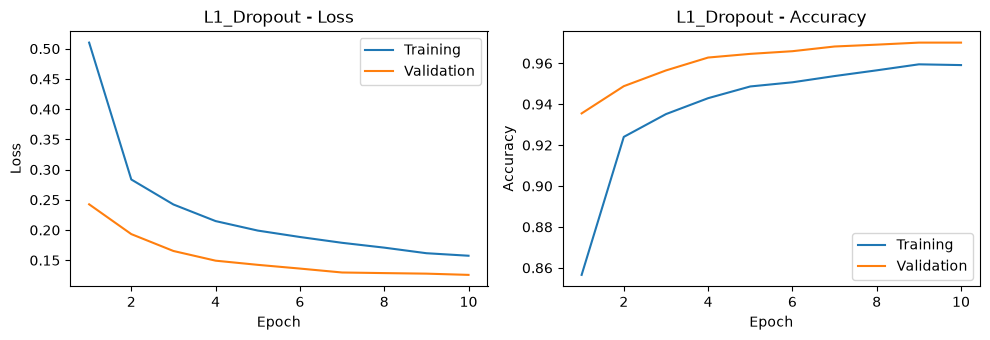

In [71]:
results.append(run_scenario("L1_Dropout"))

## Summary

FINAL RESULTS
     Scenario  Test Loss  Test Accuracy  Epochs Run
     baseline   0.088972         0.9727          10
           L1   0.116572         0.9716          10
           L2   0.089721         0.9743          10
      Dropout   0.103228         0.9694          10
EarlyStopping   0.092626         0.9727          10
   L1_Dropout   0.125805         0.9701          10


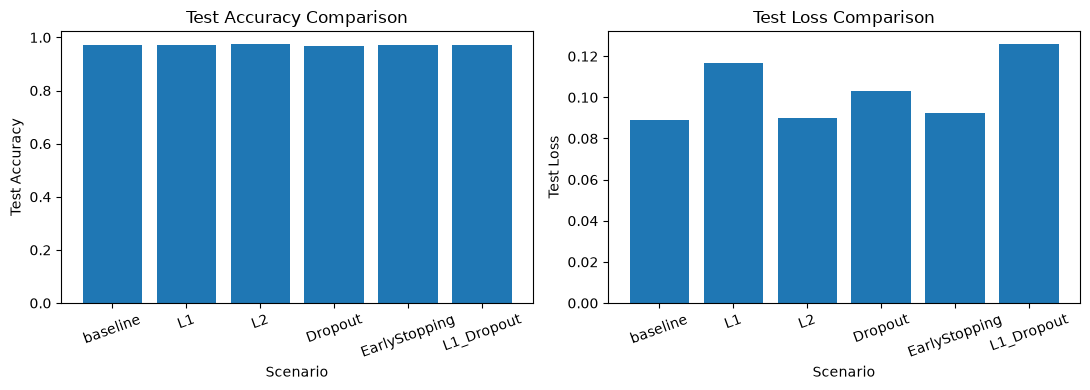

In [72]:
summary = pd.DataFrame([
    {
        "Scenario": r["scenario"],
        "Test Loss": r["test_loss"],
        "Test Accuracy": r["test_accuracy"],
        "Epochs Run": r["epochs_run"],
    }
    for r in results
])

print("FINAL RESULTS")
print(summary.to_string(index=False))

summary.to_csv(
    os.path.join("results", "summary.csv"),
    index=False
)

fig, (ax_acc, ax_loss) = plt.subplots(1, 2, figsize=(11, 4))

ax_acc.bar(summary["Scenario"], summary["Test Accuracy"])
ax_acc.set_ylabel("Test Accuracy")
ax_acc.set_xlabel("Scenario")
ax_acc.set_title("Test Accuracy Comparison")
ax_acc.tick_params(axis="x", rotation=20)

ax_loss.bar(summary["Scenario"], summary["Test Loss"])
ax_loss.set_ylabel("Test Loss")
ax_loss.set_xlabel("Scenario")
ax_loss.set_title("Test Loss Comparison")
ax_loss.tick_params(axis="x", rotation=20)

fig.tight_layout()
plt.show()